<a href="https://colab.research.google.com/github/SilviaVenturini/python-air-disasters-analysis/blob/main/Analysis_of_Aviation_Disasters_from_1919_to_2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Data cleaning.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/aviation-accidents.csv"

df = pd.read_csv(URL) # Import the CSV file.
df_copy = df.copy()
df_copy.info()

df_copy["date"] = pd.to_datetime(df_copy["date"], errors="coerce") # Convert to datetime; "coerce" handles dirty data like "date unk."
df_copy["year"] = pd.to_numeric(df_copy["year"], errors="coerce")

df_copy = df_copy.dropna(subset= ["date","year"]) # Remove records where time/year context is missing.
df_copy["year"] = df_copy["year"].astype(int)

# Standardize missing values.
df_copy["registration"] = df_copy["registration"].fillna("-")
df_copy["operator"] = df_copy["operator"].fillna("Unknown")
df_copy["location"] = df_copy["location"].fillna("Unknown")
df_copy["country"] = df_copy["country"].fillna("Unknown")
df_copy["country"] = df_copy["country"].replace("Unknown country", "Unknown")

# Remove leading/trailing whitespace from all string ("object") columns.
columns_stripped = df_copy.select_dtypes(include= ["object"]).columns
for col in columns_stripped:
  df_copy[col] = df_copy[col].str.strip()

# Clean fatalities strings (for example "21+6") by summing parts
new_fatalities = []
for value in df_copy["fatalities"]:
  str_value = str(value).strip()

  if "+" in str_value:
    v_split = str_value.split("+")
    fatalities_sum = 0
    for i in v_split:
      i = i.strip()
      if i.isnumeric():
        fatalities_sum += int(i)
    new_fatalities.append(fatalities_sum)

  elif str_value.isnumeric():
    new_fatalities.append(int(str_value))

  else:
    new_fatalities.append(None)

df_copy["fatalities"] = new_fatalities
df_copy["fatalities"] = pd.to_numeric(df_copy["fatalities"], errors="coerce").astype("Int64") # Cast to nullable Int64 to allow NaN without converting to float.

df_copy.info() # After data cleaning and manipulation, the DataFrame size decreased from 23,966 to 23,408 rows.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23967 entries, 0 to 23966
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          23967 non-null  object
 1   type          23967 non-null  object
 2   registration  22419 non-null  object
 3   operator      23963 non-null  object
 4   fatalities    20029 non-null  object
 5   location      23019 non-null  object
 6   country       23967 non-null  object
 7   cat           23967 non-null  object
 8   year          23967 non-null  object
dtypes: object(9)
memory usage: 1.6+ MB


/tmp/ipykernel_4298/3334410215.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_copy["date"] = pd.to_datetime(df_copy["date"], errors="coerce") # Convert to datetime; "coerce" handles dirty data like "date unk."


<class 'pandas.core.frame.DataFrame'>
Index: 23408 entries, 61 to 23966
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          23408 non-null  datetime64[ns]
 1   type          23408 non-null  object        
 2   registration  23408 non-null  object        
 3   operator      23408 non-null  object        
 4   fatalities    19803 non-null  Int64         
 5   location      23408 non-null  object        
 6   country       23408 non-null  object        
 7   cat           23408 non-null  object        
 8   year          23408 non-null  int64         
dtypes: Int64(1), datetime64[ns](1), int64(1), object(6)
memory usage: 1.8+ MB


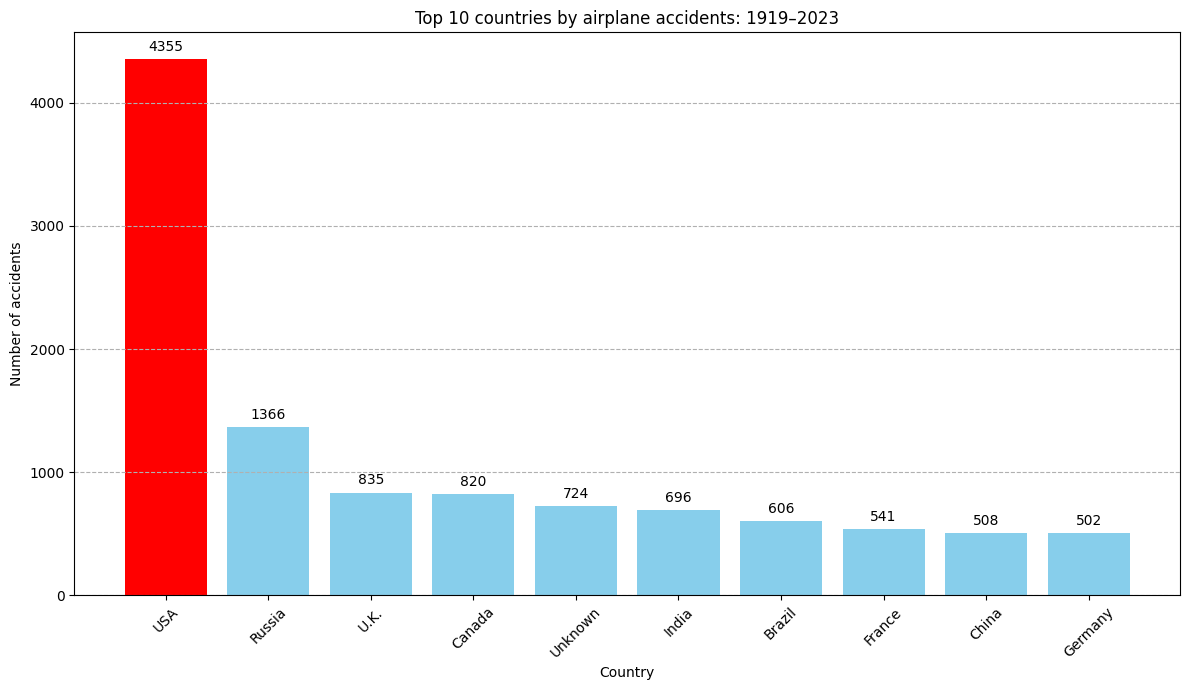

In [ ]:
# Get the top 10 countries by incident frequency.
accidents_by_country = df_copy["country"].value_counts().head(10).reset_index()
accidents_by_country.columns = ["Country", "Number of accidents"]

# Highlight the top country in red.
bar_color = ["red"] + ["skyblue"]*9
plt.figure(figsize=(12, 7))
plt.bar(accidents_by_country["Country"], accidents_by_country["Number of accidents"], color= bar_color)

# Identify the maximum number of accidents to scale the Y-axis and position labels.
# Add value labels on top of each bar for better readability.
max_val = accidents_by_country["Number of accidents"].max()
for x, y in zip(accidents_by_country["Country"], accidents_by_country["Number of accidents"]):
  plt.text(x, y + (max_val * 0.015), str(y), ha= "center")

# Vertical bar chart visualization.
plt.title("Top 10 countries by airplane accidents: 1919–2023")
plt.xlabel("Country")
plt.ylabel("Number of accidents")
plt.xticks(rotation=45)
plt.grid(axis= "y", linestyle= "--")
plt.tight_layout()
plt.show()


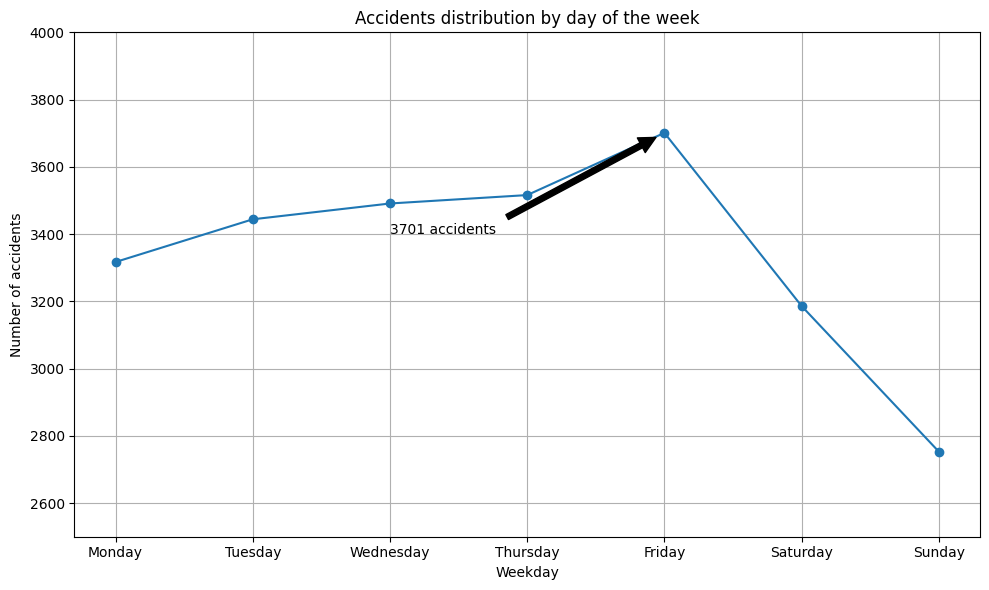

In [ ]:
# Extract the day name from the date and count frequencies.
df_copy["Weekday"] = df_copy["date"].dt.day_name()
accidents_per_day = df_copy["Weekday"].value_counts()
df_day = accidents_per_day.reset_index()
df_day.columns = ["Weekday", "Number of accidents"]

ordered_week_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Reorder the days of the week using pd.Categorical from Monday to Friday.
df_day["Weekday"] = pd.Categorical(df_day["Weekday"], categories= ordered_week_days, ordered=True)
df_days = df_day.sort_values("Weekday")

# Line chart visualization.
plt.figure(figsize=(10, 6))
plt.plot(df_days["Weekday"], df_days["Number of accidents"], marker="o")
plt.title("Accidents distribution by day of the week")
plt.xlabel("Weekday")
plt.ylabel("Number of accidents")
plt.grid()
plt.annotate("3701 accidents", xy= ("Friday", 3701), xytext= ("Wednesday", 3400), arrowprops=dict(facecolor='black', shrink=0.05)) # Highlight that Friday is the peak day.
plt.ylim(2500, 4000) # Set Y-axis limits.
plt.tight_layout()
plt.show()

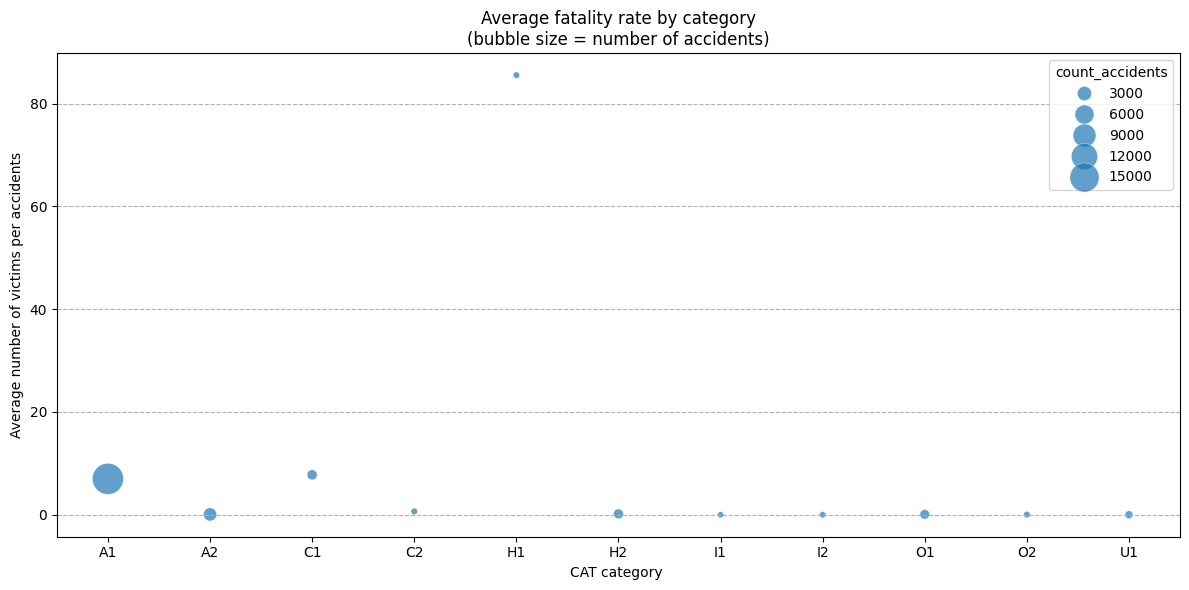

In [ ]:
# Remove records with missing year and create a "decade" column by grouping years (for example 1995 becomes 1990).
df_copy = df_copy.dropna(subset= ["year"]).copy()
df_copy["decade"] = (df_copy["year"]//10) * 10

# Transform "fatalities" in a number; convert errors to NaN and replace them with 0.
df_copy["fatalities"] = pd.to_numeric(df_copy['fatalities'], errors='coerce').fillna(0)

# Fill missing incident categories with "U1".
df_copy["cat"] = df_copy["cat"].fillna("U1")

# Create a dictionary to group ASN categories into general categories.
resilience_category = {
    "A1": "Catastrophic loss", "C1": "Catastrophic loss", # Fatal/Total loss
    "A2": "Managed outcome", "I1": "Managed outcome", "I2": "Managed outcome", "C2": "Managed outcome", # Emergencies managed
    "H1": "Other", "H2": "Other", "O1": "Other", "O2": "Other", "U1": "Other", "U2": "Other"
}

df_copy["Resilience category"] = df_copy["cat"].map(resilience_category).fillna("Other")

# Classify incidents as "Security" and "Safety"
df_copy["Type threat"] = df_copy["cat"].apply( lambda x:"Security" if "H" in str(x) else "Safety" )

# Group by CAT to calculate the lethality and the frequency of events
lethality = df_copy.groupby("cat").agg(
    mean_fatalities= ("fatalities", "mean"),
    count_accidents= ("cat", "size")
).reset_index()

# Use Seaborn to create a bubble chart representing lethality vs. category.
plt.figure(figsize=(12, 6))
sns.scatterplot(data=lethality, x= "cat", y= "mean_fatalities", size= "count_accidents", sizes=(20, 500), alpha=0.7)
plt.title("Average fatality rate by category\n(bubble size = number of accidents)")
plt.ylabel("Average number of victims per accidents")
plt.xlabel("CAT category ")
plt.grid(axis= "y", linestyle= "--")
plt.tight_layout()
plt.show()

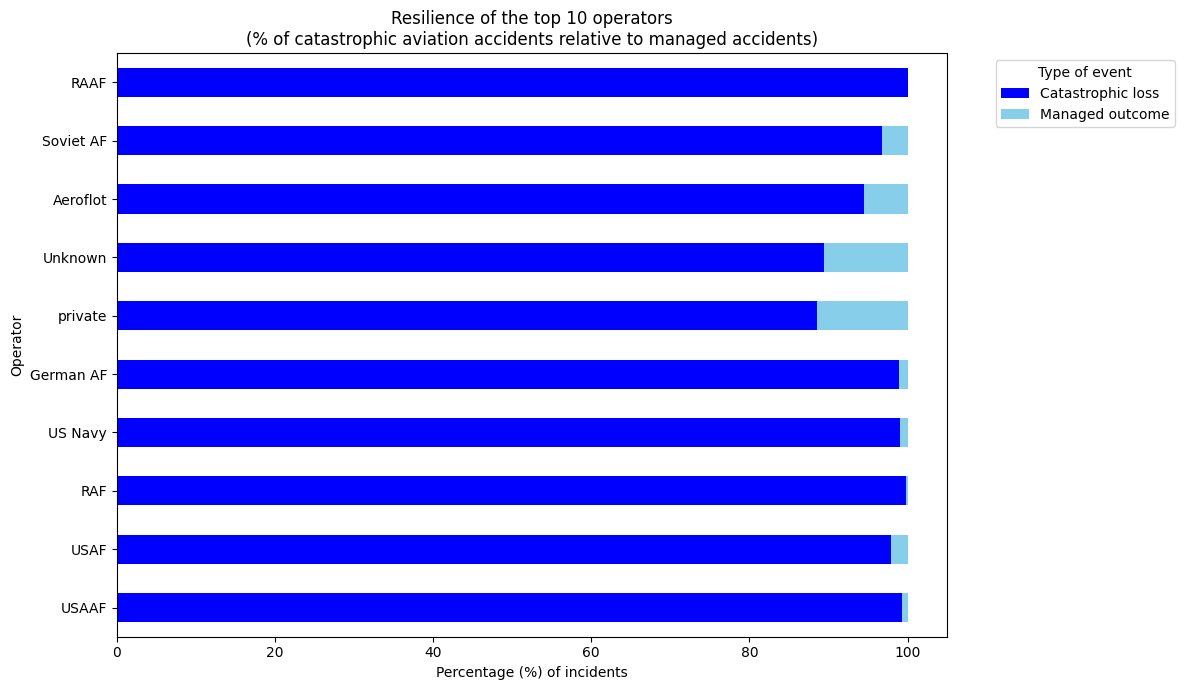

In [ ]:
# Exclude non-flight categories (like ground operations or security).
# Focus only on "Catastrophic" vs "Resilient" flight outcomes.
df_flight = df_copy[df_copy["Resilience category"] != "Other"].copy()

# Count incidents per operator and select the names (index) of the top 10 most frequent ones.
top_operator_flight = df_flight["operator"].value_counts().head(10).index

# Filter the dataset to keep only records belonging to these 10 operators.
df_top_flight = df_flight[df_flight["operator"].isin(top_operator_flight)]

# Create a cross-tabulation between operators and their resilience outcomes.
# Calculate percentages for each operator (normalize=index creates 0-1 scale, *100 makes it 0-100%).
resilience_pivot = pd.crosstab(df_top_flight["operator"], df_top_flight["Resilience category"], normalize= "index") * 100


# Sort the pivot table rows according to the “top 10” frequency ranking.
resilience_pivot = resilience_pivot.reindex(top_operator_flight)

# Create a horizontal stacked bar chart. "Blue" = Catastrophic Loss, "skyblue" = Managed outcome
resilience_pivot.plot(kind="barh", stacked=True, figsize=(12, 7), color=["blue", "skyblue"])
plt.title("Resilience of the top 10 operators\n(% of catastrophic aviation accidents relative to managed accidents)")
plt.xlabel("Percentage (%) of incidents")
plt.ylabel("Operator")
plt.legend(title="Type of event", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

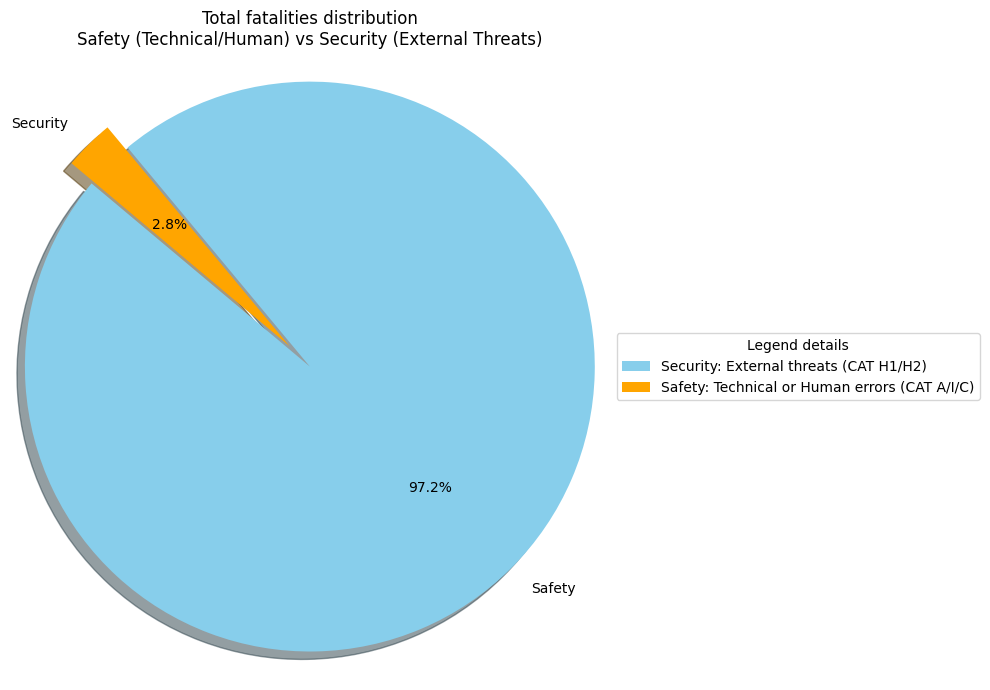

In [ ]:
# Group data by "Type threat" (Safety/Security) and sum all fatalities for each group.
security_fatalities = df_copy.groupby("Type threat")["fatalities"].sum()

# Pie chart visualization
# autopct: display the percentage with one decimal place(for example 2.8%).
# startangle: rotate the chart by 140 degrees for better visual balance.
# explode: pull the first slice (Security) slightly out for emphasis.
# shadow: add a 3D effect for better depth.
plt.figure(figsize=(10, 7))
plt.pie(security_fatalities, labels=security_fatalities.index, autopct='%1.1f%%',
        startangle=140, colors=["skyblue", "orange"], explode=(0.1, 0), shadow=True)

# Custom labels to explain what each category represents
legend_labels = [
    "Security: External threats (CAT H1/H2)",
    "Safety: Technical or Human errors (CAT A/I/C)"
]
plt.legend(legend_labels, title= "Legend details", loc= "center left", bbox_to_anchor= (1, 0.5))

plt.title("Total fatalities distribution\nSafety (Technical/Human) vs Security (External Threats)")
plt.axis("equal")
plt.tight_layout()
plt.show()

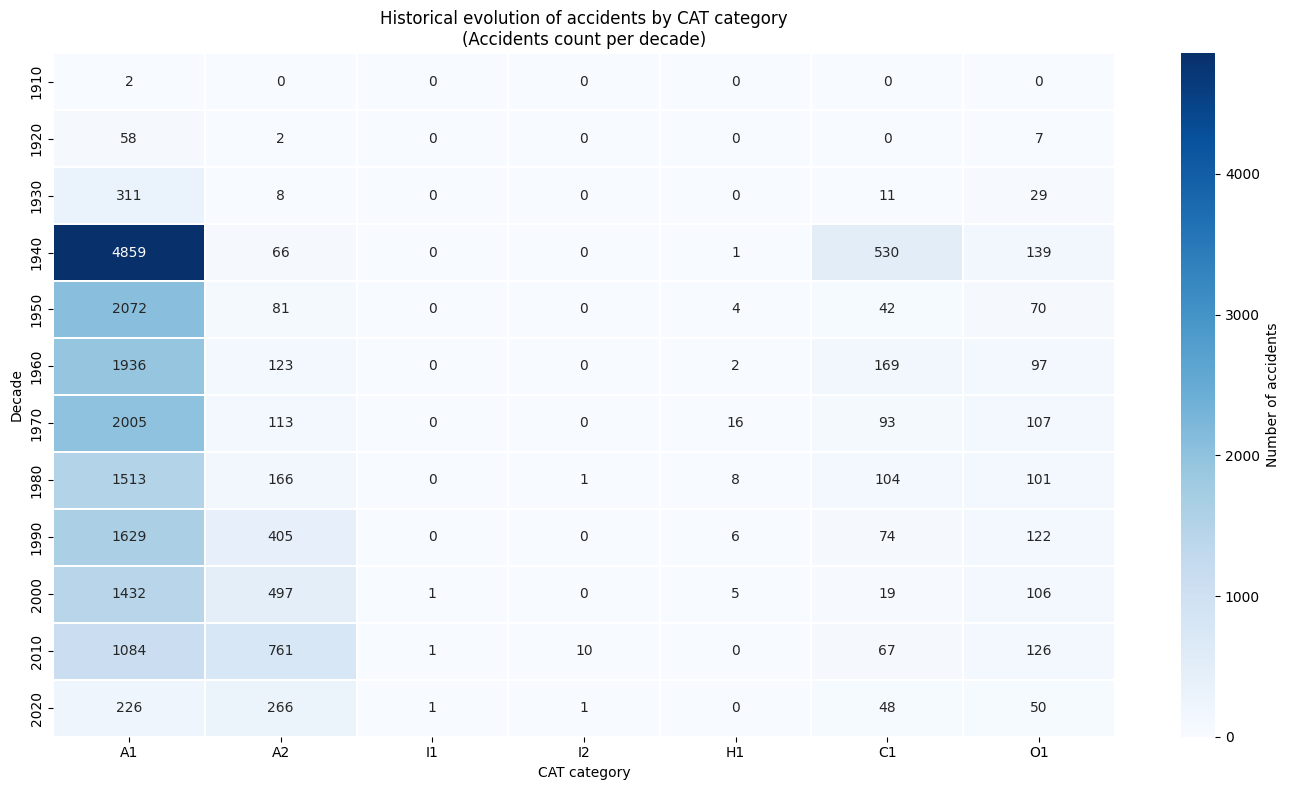

In [ ]:
# Group by decade and category, then count occurrences.
# .unstack() moves 'cat' from rows to columns to create a matrix (grid).
# .fillna(0) replaces NaN values with 0 for decades that have no incidents in a specific category.
decade_pivot = df_copy.groupby(["decade", "cat"]).size().unstack(fill_value=0)

# Reindex to keep only selected categories, then replace missing values with 0.
main_cats = ["A1", "A2", "I1", "I2", "H1", "C1", "O1"]
decade_pivot = decade_pivot.reindex(columns=main_cats).fillna(0)

# Convert the pivot table to long format (including zero-count categories)
decade_long = decade_pivot.stack().reset_index()
decade_long.columns = ["Decade", "Category", "Number of accidents"]

plt.figure(figsize=(14, 8))
sns.heatmap(data= decade_pivot, cmap= "Blues", annot= True, fmt= "g", linewidths=.20, cbar_kws={"label": "Number of accidents"})
plt.title("Historical evolution of accidents by CAT category\n(Accidents count per decade)")
plt.xlabel("CAT category")
plt.ylabel("Decade")
plt.tight_layout()
plt.show()

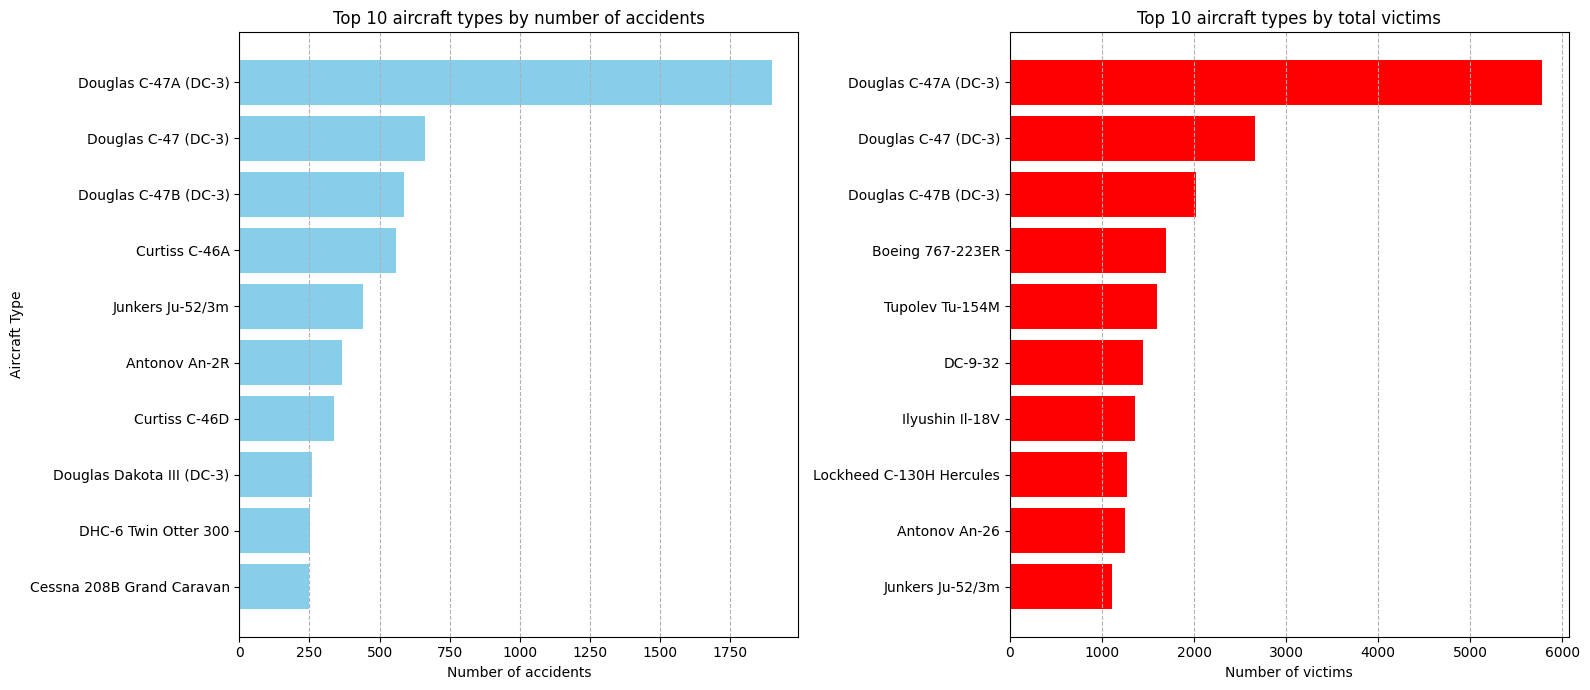

In [ ]:
# Filter data and exclude "unknown" or "private" aircraft types.
df_filter_type = df_copy[~df_copy["type"].str.contains("unknown|private", case = False, na = True)].copy()

# Rank top 10 aircraft types by accident frequency.
aircraft_type_incident = df_filter_type["type"].value_counts().head(10).reset_index()
aircraft_type_incident.columns = ["Type", "Number of accidents"]

# Rank top 10 aircraft types by total fatalities.
# Group by aircraft type and sum the victims, sorting from highest to lowest.
aircraft_type_fatalities = df_filter_type.groupby("type")["fatalities"].sum().sort_values(ascending= False).head(10).reset_index()
aircraft_type_fatalities.columns = ["Type", "Number of victims"]

# Side-by-side comparison visualization.
plt.figure(figsize=(16, 7))

# Left Subplot: Accidents Count per Aircraft Type.
plt.subplot(1,2,1)
plt.barh(aircraft_type_incident["Type"], aircraft_type_incident["Number of accidents"], color="skyblue")
plt.title("Top 10 aircraft types by number of accidents")
plt.xlabel("Number of accidents")
plt.ylabel("Aircraft Type")
plt.gca().invert_yaxis() # Highest counts at the top.
plt.grid(axis='x', linestyle='--')

# Right Subplot: Victims Count per Aircraft Type.
plt.subplot(1,2,2)
plt.barh(aircraft_type_fatalities["Type"], aircraft_type_fatalities["Number of victims"], color="red")
plt.title("Top 10 aircraft types by total victims")
plt.xlabel("Number of victims")
plt.gca().invert_yaxis() # Highest fatalities at the top.
plt.grid(axis='x', linestyle='--')

plt.tight_layout()
plt.show()


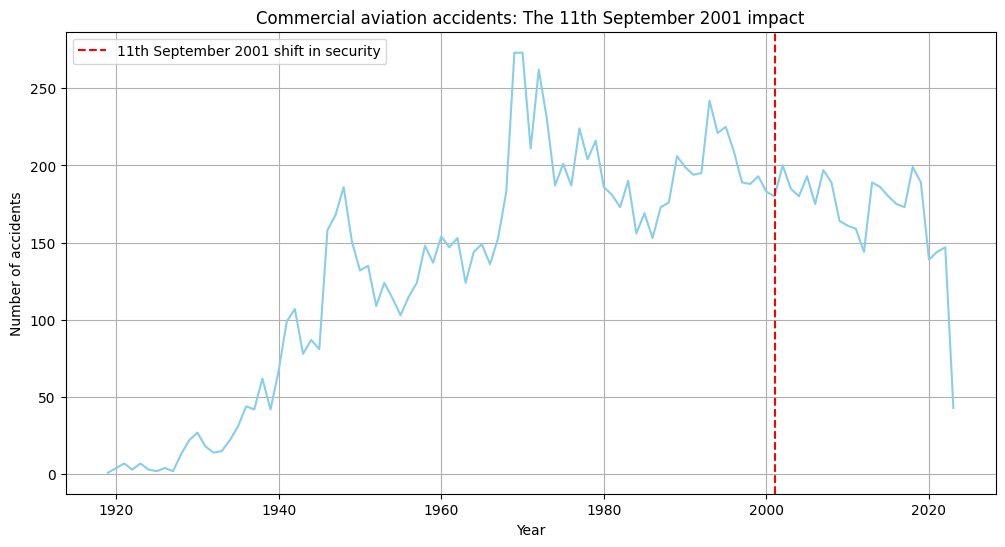

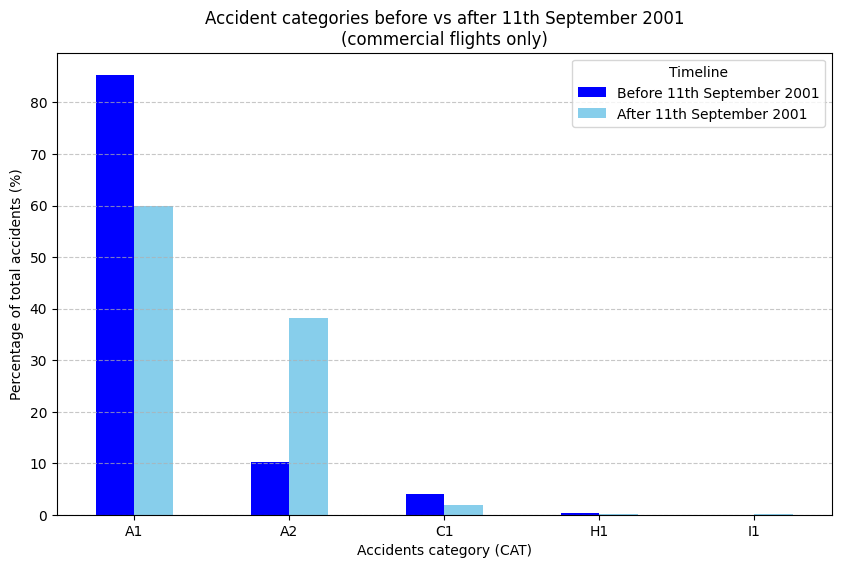

In [ ]:
# Define a pattern for military and private flight
military_flight = "Force|Navy|Army|Air Force|AF|Militaires|Militari|Guard"
private_flight = "Private|Executive|Club|Flight School"

# Filter out military and private/non-commercial flights
df_commercial = df_copy[
    (~df_copy["operator"].str.contains(military_flight, case=False, na=False)) &
    (~df_copy["operator"].str.contains(private_flight, case=False, na=False))
].copy()

# Clean data for fatalities and dates
df_commercial = df_commercial.dropna(subset=["date", "cat"]).copy()

# # Define 11th September 2001 as a reference point and categorize accidents before and after 11th September 2001.
eleven_sept = pd.Timestamp("2001-09-11")
df_commercial["Period"] = df_commercial["date"].apply(lambda x: "After 11th September 2001" if x >= eleven_sept else "Before 11th September 2001")

# Grouping by year for the trend
year_trends = df_commercial.groupby("year").size().reset_index(name= "accident_count")

plt.figure(figsize=(12, 6))
plt.plot(year_trends["year"], year_trends["accident_count"], color= "skyblue")
plt.axvline(x= 2001, color= "red", linestyle= "--", label= "11th September 2001 shift in security")
plt.title("Commercial aviation accidents: The 11th September 2001 impact")
plt.xlabel("Year")
plt.ylabel("Number of accidents")
plt.legend()
plt.grid()
plt.show()

# Filter only for the main categories to avoid clutter
relevant_cats = ["A1", "A2", "H1", "C1", "I1"]
df_filtered_cats = df_commercial[df_commercial["cat"].isin(relevant_cats)].copy()

# Create a cross-tabulation: Period vs Category
cat_comparison = pd.crosstab(df_filtered_cats["cat"], df_filtered_cats["Period"], normalize= "columns") * 100
cat_comparison = cat_comparison[cat_comparison.columns[::-1]] # Reverse the column order

# Visualization with a grouped bar chart
cat_comparison.plot(kind= "bar", color= ["blue", "skyblue"], figsize=(10, 6))
plt.title("Accident categories before vs after 11th September 2001\n(commercial flights only)")
plt.ylabel("Percentage of total accidents (%)")
plt.xlabel("Accidents category (CAT)")
plt.xticks(rotation=0)
plt.legend(title="Timeline")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# Exclude "Unknown", oceans, and symbols and keep only valid countries that could be mapped
df_clean = df_copy[~df_copy["country"].isin(["Unknown", "?", "Atlantic Ocean", "Pacific Ocean", "Indian Ocean", "Arctic Ocean"])].copy()

# Clean and standardize country names.
# Removing leading/trailing whitespaces and standardize capitalization of country names.
df_clean["country"] = df_clean["country"].str.strip().str.title()
country_counts = df_clean["country"].value_counts().reset_index()
country_counts.columns = ["Country", "Number of accidents"]

# Counting occurrences per country to create a frequency table.
country_counts = df_clean["country"].value_counts().reset_index()
country_counts.columns = ["Country", "Number of accidents"]

# Generate World Map.
# Use "country names" mode to automatically match strings with geographic coordinates.
map = px.choropleth(country_counts,
                    locations= "Country", # Column with country names.
                    locationmode= "country names", # Match names to the Plotly's map.
                    color= "Number of accidents", # Set the color intensity.
                    hover_name= "Country", # Show the name when you point at it.
                    color_continuous_scale= px.colors.sequential.Reds, # Visual scale from light to dark red.
                    title= "Global distribution of aviation accidents (1919–2023)")
map.show()